# Analyze `optuna_search.py` results

Reads everything downloaded from CARC into `./results/`, plus `best_test_raw.csv`
(from `python evaluate_test.py --outdir results`, run once the winning config is locked in)
and the noise-condition breakdown (`analyze_noise_effect.py`, run inline below).

**Scope note:** the search-space comparison (precision/recall scatter, F1 heatmap across
every method x cost combo Optuna tried) is **train-only**. `optuna_trials.csv` has an
aggregated score for every config Optuna actually sampled, but `best_validation_raw.csv`/
`best_test_raw.csv` only ever score the single *winning* config -- validation and test were
each deliberately spent once, on the winner, not re-run for every candidate. So there's no
validation/test equivalent of the search-space plots below without deliberately re-running
detection for other configs against those splits.

In [1]:
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from IPython.display import Image, display

RESULTS_DIR = "results"
METHODS_DIR = os.path.abspath("..")   # Methods/ -- for analyze_noise_effect.py
sys.path.insert(0, METHODS_DIR)

with open(os.path.join(RESULTS_DIR, "best_params.json")) as f:
    best_params = json.load(f)
OBJECTIVE = best_params.get("objective", "warming")

trials_df = pd.read_csv(os.path.join(RESULTS_DIR, "optuna_trials.csv"))
conv_df = pd.read_csv(os.path.join(RESULTS_DIR, "optuna_convergence.csv"))
train_df = pd.read_csv(os.path.join(RESULTS_DIR, "best_train_raw.csv"))
val_df = pd.read_csv(os.path.join(RESULTS_DIR, "best_validation_raw.csv"))

test_csv = os.path.join(RESULTS_DIR, "best_test_raw.csv")
test_df = pd.read_csv(test_csv) if os.path.exists(test_csv) else None
if test_df is None:
    print(f"{test_csv} not found -- run `python evaluate_test.py --outdir {RESULTS_DIR}` "
          "first to score the winning config on held-out TEST (one-time; see its docstring).")

print(f"objective optimized: f1_{OBJECTIVE}")
best_params

objective optimized: f1_warming


{'method': 'KernelCPD',
 'cost': 'linear',
 'pen': 8.34753880040116,
 'n_bkps': None,
 'min_size': 20,
 'jump': 1,
 'trial_number': 59,
 'objective': 'warming',
 'train_f1_all': 0.5884728126548552,
 'train_f1_warming': 0.5691074793983074,
 'train_f1_cooling': 0.5989474507874382,
 'train_mean_elapsed_s': 0.013420511623068402,
 'run_metadata': {'wall_time_s': 84279.10990793305,
  'n_trials_this_run': 118,
  'n_trials_total': 118,
  'n_failed_total': 8,
  'patience': 80,
  'min_trials': 100,
  'min_delta': 0.01,
  'stopped_early': False,
  'stopped_at_trial': None}}

## Trial states and convergence

trials total: 118
state
COMPLETE    110
FAIL          8
Name: count, dtype: int64


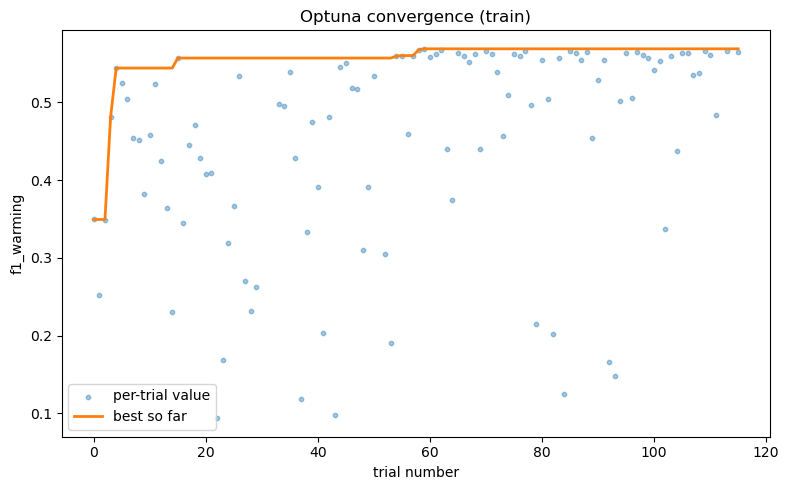

In [2]:
print(f"trials total: {len(trials_df)}")
print(trials_df['state'].value_counts())

fig, ax = plt.subplots(figsize=(8, 5))
complete = trials_df[trials_df['state'] == 'COMPLETE'].sort_values('number')
ax.scatter(complete['number'], complete['value'], s=10, alpha=0.4, label='per-trial value')
ax.plot(conv_df['number'], conv_df['best_value_so_far'], color='C1', linewidth=2, label='best so far')
ax.set_xlabel('trial number')
ax.set_ylabel(f"f1_{OBJECTIVE}")
ax.set_title('Optuna convergence (train)')
ax.legend()
fig.tight_layout()

## Failed / crashed trials

Some trials error out mid-detection (e.g. a worker OOM-crash) and get caught, marked `COMPLETE` with a fallback `value=0.0`, but `user_attrs_mean_f1_*` stays `NaN` -- these are why some cells in the plots below can be entirely blank rather than just low-scoring. Worth checking before reading too much into any method's absence.

In [3]:
if 'user_attrs_error' in trials_df.columns:
    error_mask = trials_df['user_attrs_error'].notna()
else:
    error_mask = pd.Series(False, index=trials_df.index)

print(f"{error_mask.sum()} / {len(trials_df)} trials recorded an error")
if error_mask.any():
    by_method = trials_df.loc[error_mask, 'params_method'].value_counts()
    print("\nerrors by method:")
    print(by_method)
    print("\nsample error message per method:")
    for method, grp in trials_df.loc[error_mask].groupby('params_method'):
        msg = grp['user_attrs_error'].iloc[0]
        print(f"  {method}: {msg[:160]}")
else:
    print("No trials recorded an error attribute in this run.")


8 / 118 trials recorded an error

errors by method:
params_method
Pelt    8
Name: count, dtype: int64

sample error message per method:
  Pelt: RuntimeError: Error predicting breakpoints with Pelt.
Parameters: pen=9.826357669281942, n_bkps=None
Original error: _detect exceeded --max-call-seconds


## Search-space overview (train, every trial Optuna tried)

Optuna's grouped/conditional search space stores `cost` and `pen` in per-method columns
(`params_cost_<Method>`, `params_pen_<Method>_<cost>`) that are non-null only for the method
that particular trial actually used. `unify_trial_params` reconstructs a single
`(method, cost, pen)` view, one row per trial, so every trial -- not just the winner -- can
be plotted together.

In [4]:
def unify_trial_params(row):
    method = row.get('params_method')
    if pd.isna(method):
        return pd.Series({'method': np.nan, 'cost': np.nan, 'pen': np.nan})
    cost = row.get(f'params_cost_{method}', np.nan)
    pen = np.nan
    if pd.notna(cost):
        pen = row.get(f'params_pen_{method}_{cost}', np.nan)
    return pd.Series({'method': method, 'cost': cost, 'pen': pen})

unified = trials_df.apply(unify_trial_params, axis=1)
trials_unified = pd.concat([trials_df, unified], axis=1)
trials_unified = trials_unified[trials_unified['state'] == 'COMPLETE'].copy()

trials_unified['train_precision'] = trials_unified[f'user_attrs_mean_precision_{OBJECTIVE}']
trials_unified['train_recall'] = trials_unified[f'user_attrs_mean_recall_{OBJECTIVE}']
trials_unified['train_f1'] = trials_unified[f'user_attrs_mean_f1_{OBJECTIVE}']

METHODS_SEEN = sorted(trials_unified['method'].dropna().unique())
COST_ORDER = sorted(trials_unified['cost'].dropna().unique())
print(f"{len(trials_unified)} COMPLETE trials across {len(METHODS_SEEN)} methods, "
      f"{len(COST_ORDER)} cost functions")
trials_unified['method'].value_counts()

110 COMPLETE trials across 4 methods, 7 cost functions


method
KernelCPD    73
Pelt         16
Binseg       11
BottomUp     10
Name: count, dtype: int64

In [5]:
# categorical palette: color = cost function, shape = method (independent legends below)
NEUTRAL = "#898781"
COST_PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7",
                "#e34948", "#17becf", "#a0522d", "#cc79a7"]
COST_COLORS = {c: COST_PALETTE[i % len(COST_PALETTE)] for i, c in enumerate(COST_ORDER)}
COST_LABELS = {"l1": r"$\ell_1$", "l2": r"$\ell_2$"}
def cost_label(c):
    return COST_LABELS.get(c, c)

MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]
METHOD_MARKERS = {m: MARKERS[i % len(MARKERS)] for i, m in enumerate(METHODS_SEEN)}

SEQUENTIAL_BLUE = LinearSegmentedColormap.from_list("seq_blue", [
    "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

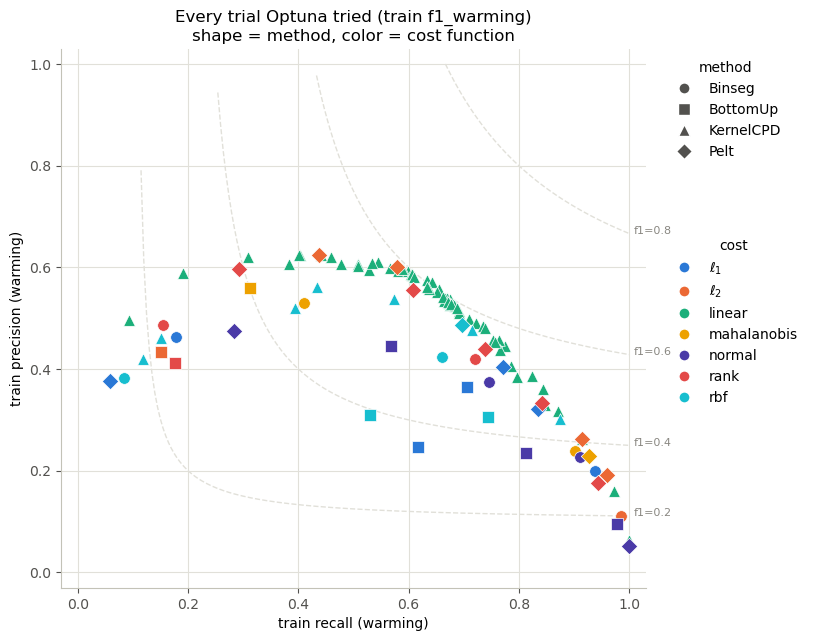

In [6]:
def plot_precision_recall(df, methods, costs, markers, colors, objective):
    fig, ax = plt.subplots(figsize=(9.5, 7))

    r = np.linspace(0.01, 1, 200)
    for f1_target in [0.2, 0.4, 0.6, 0.8]:
        with np.errstate(divide="ignore", invalid="ignore"):
            p = f1_target * r / (2 * r - f1_target)
        mask = (p > 0) & (p <= 1)
        ax.plot(r[mask], p[mask], color="#e1e0d9", linewidth=1, linestyle="--", zorder=0)
        if mask.any():
            xi = np.where(mask)[0][-1]
            ax.annotate(f"f1={f1_target}", (r[xi], p[xi]), color="#898781", fontsize=8,
                        xytext=(3, 0), textcoords="offset points")

    for method in methods:
        for cost in costs:
            sub = df[(df["method"] == method) & (df["cost"] == cost) & (df["train_f1"] > 0)]
            if sub.empty:
                continue
            ax.scatter(sub["train_recall"], sub["train_precision"],
                       color=colors.get(cost, NEUTRAL), marker=markers.get(method, "o"),
                       s=70, zorder=3, edgecolor="white", linewidth=0.5)

    ax.set_xlabel(f"train recall ({objective})")
    ax.set_ylabel(f"train precision ({objective})")
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.03, 1.03)
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_title(f"Every trial Optuna tried (train f1_{objective})\nshape = method, color = cost function")

    # both legends moved outside the axes (right margin, stacked) instead of
    # "lower left"/"lower right" inside the plot -- those overlapped scatter points and
    # made some entries hard to read, especially where markers cluster near a corner.
    method_handles = [Line2D([0], [0], marker=markers.get(m, "o"), linestyle="none",
                              markerfacecolor="#52514e", markeredgecolor="white",
                              markersize=8, label=m) for m in methods]
    cost_handles = [Line2D([0], [0], marker="o", linestyle="none",
                            markerfacecolor=colors.get(c, NEUTRAL), markeredgecolor="white",
                            markersize=8, label=cost_label(c)) for c in costs]
    method_legend = ax.legend(handles=method_handles, title="method", frameon=False,
                               loc="upper left", bbox_to_anchor=(1.02, 1.0))
    ax.add_artist(method_legend)
    ax.legend(handles=cost_handles, title="cost", frameon=False,
              loc="upper left", bbox_to_anchor=(1.02, 1.0 - 0.055 * (len(methods) + 2)))

    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.grid(color="#e1e0d9", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(colors="#52514e")
    fig.subplots_adjust(right=0.74)   # reserve room for the legends outside the axes
    return fig

fig = plot_precision_recall(trials_unified, METHODS_SEEN, COST_ORDER, METHOD_MARKERS, COST_COLORS, OBJECTIVE)
plt.show()

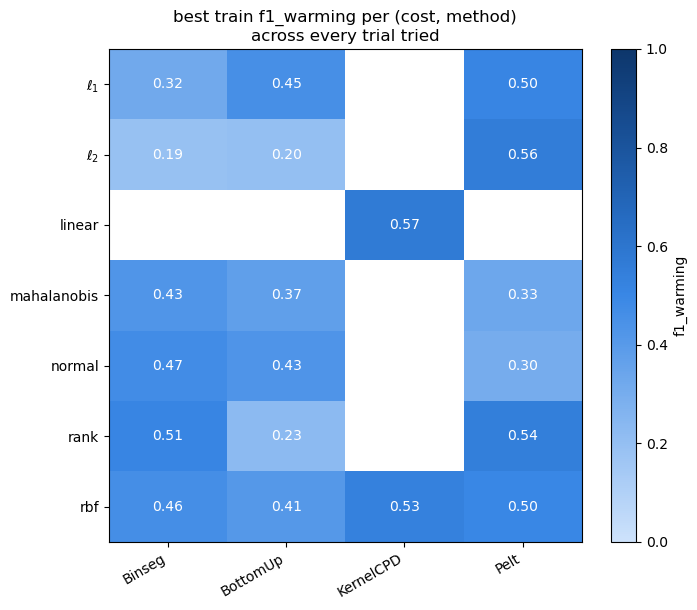

In [7]:
def plot_f1_heatmap(df, methods, costs, objective):
    # best-over-grid per (cost, method) cell -- each cell can hide several pen/min_size
    # trials for that combo; take the best one, same "conclusion" semantics as the old
    # pre-Optuna grid search's per-method conclusion.csv.
    best_per_cell = df.groupby(['cost', 'method'])['train_f1'].max().reset_index()
    pivot = best_per_cell.pivot(index='cost', columns='method', values='train_f1')
    pivot = pivot.reindex(index=[c for c in costs if c in pivot.index],
                           columns=[m for m in methods if m in pivot.columns])

    fig, ax = plt.subplots(figsize=(1.3 * len(pivot.columns) + 2, 0.6 * len(pivot.index) + 2))
    im = ax.imshow(pivot.values, cmap=SEQUENTIAL_BLUE, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=30, ha='right')
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels([cost_label(c) for c in pivot.index])
    ax.set_title(f"best train f1_{objective} per (cost, method)\nacross every trial tried")
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.values[i, j]
            if pd.notna(val):
                ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                        color="white" if val < 0.6 else "black")
    fig.colorbar(im, ax=ax, label=f"f1_{objective}")
    fig.tight_layout()
    return fig

fig = plot_f1_heatmap(trials_unified, METHODS_SEEN, COST_ORDER, OBJECTIVE)
plt.show()

## Winning config: train vs. validation vs. test

Per-series breakdown for the single winning config, split by direction (`all` / `warming` / `cooling`).

In [8]:
metric_cols = [c for c in train_df.columns if c.startswith(('precision_', 'recall_', 'f1_'))]

summary_data = {'train_mean': train_df[metric_cols].mean(), 'val_mean': val_df[metric_cols].mean()}
if test_df is not None:
    summary_data['test_mean'] = test_df[metric_cols].mean()
summary = pd.DataFrame(summary_data)
summary

,train_mean,val_mean,test_mean
precision_all,0.594513,0.598359,0.603686
recall_all,0.658536,0.590798,0.634666
f1_all,0.588473,0.551848,0.597954
precision_warming,0.570355,0.575302,0.565033
recall_warming,0.642572,0.565169,0.599665
f1_warming,0.569107,0.532451,0.564344
precision_cooling,0.613114,0.614185,0.631177
recall_cooling,0.659565,0.603361,0.649777
f1_cooling,0.598947,0.561027,0.616088


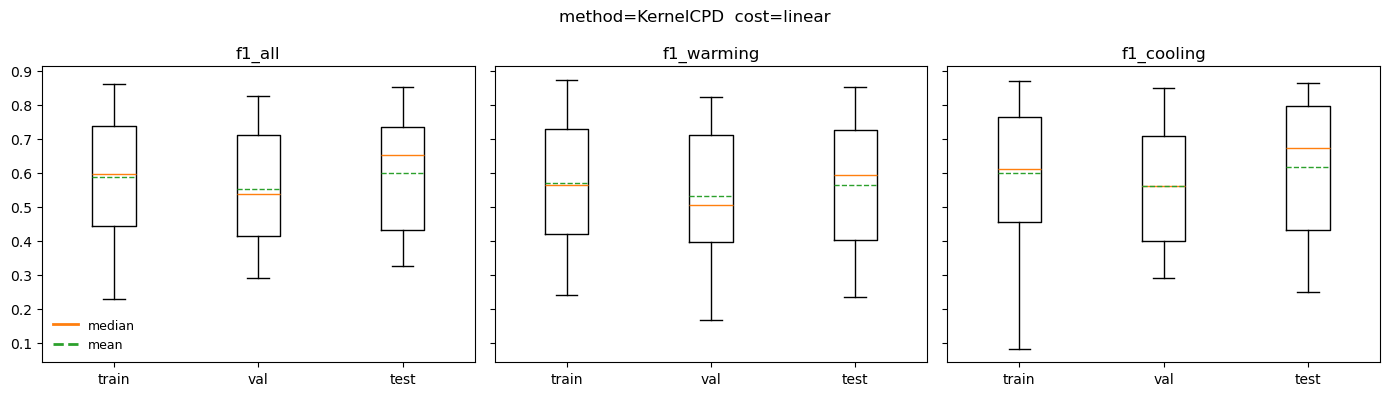

In [9]:
splits = [('train', train_df), ('val', val_df)] + ([('test', test_df)] if test_df is not None else [])

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, label in zip(axes, ('all', 'warming', 'cooling')):
    ax.boxplot(
        [df[f'f1_{label}'].dropna() for _, df in splits],
        tick_labels=[name for name, _ in splits],
        showmeans=True, meanline=True,   # mean as a dashed line (default color C2) instead of a marker
    )
    ax.set_title(f'f1_{label}')

# boxplot draws the median as a solid line (matplotlib's default 'C1' orange) and, with
# showmeans=True, meanline=True, the mean as a dashed line (default 'C2' green) --
# neither gets an automatic legend entry, so build one explicitly to avoid mixing them up.
median_handle = Line2D([0], [0], color='C1', linewidth=2, linestyle='-', label='median')
mean_handle = Line2D([0], [0], color='C2', linewidth=2, linestyle='--', label='mean')
axes[0].legend(handles=[median_handle, mean_handle], loc='lower left', frameon=False, fontsize=9)

fig.suptitle(f"method={best_params.get('method')}  cost={best_params.get('cost')}")
fig.tight_layout()

## Noise-condition effect (winning config)

The original motivating question for this whole project: how does noise **color**
(white/pink/red) and **level** (SNR) change detection performance? Reuses
`analyze_noise_effect.py` (unchanged) to join each split's per-seed scores against
`train_test_split_data/{split}_manifest.csv` by row position, then plots a color x level
heatmap. Same single-winning-config caveat as above -- this is not a method/cost sweep.

**Test only.** Train and validation were used by the optimization (config choice and sanity check),
so the noise-effect cells below score the winning config on the **test** split only -- the one split
the search never saw. Cells hold only 3-4 test series each, so read single cells as suggestive; the
controlled fixed-signal section further down has more signals per cell.

In [10]:
from analyze_noise_effect import load_merged, summarize_all_splits, plot_heatmap_row, DEFAULT_DATA_DIR, NOISIER_DATA_DIR

# precision/recall alongside f1 -- f1 can hide whether a config's failures lean toward
# missed transitions (low recall) or false alarms (low precision), which can matter more
# than f1 alone depending on the application (e.g. test is often where recall gets a
# closer look, since that's what a downstream user actually feels).
METRICS = [f'precision_{OBJECTIVE}', f'recall_{OBJECTIVE}', f'f1_{OBJECTIVE}']

# Loaded once here, reused by the three metric cells below (precision / recall / f1) --
# each one gets its own combined table (train/validation/test side by side) plus a single
# figure with all three splits' heatmaps next to each other, instead of interleaving
# split-by-split like the previous version of this cell did.
MERGED_BY_SPLIT = {}
NOISE_SPLITS = ('test',)   # unseen data only; add 'train'/'validation' for context
TEST_ONLY_DIR = os.path.join(RESULTS_DIR, 'test_only'); os.makedirs(TEST_ONLY_DIR, exist_ok=True)
for split in NOISE_SPLITS:
    merged = load_merged(RESULTS_DIR, NOISIER_DATA_DIR, split)
    if merged is None:
        print(f"[{split}] best_{split}_raw.csv not found -- skipping")
    MERGED_BY_SPLIT[split] = merged

In [11]:
metric = METRICS[0]   # precision_{OBJECTIVE}
print(f"=== {metric} by noise condition -- test only (sorted by mean) ===")
print(summarize_all_splits(MERGED_BY_SPLIT, metric, splits=NOISE_SPLITS).to_string(float_format=lambda x: f"{x:.3f}"))

=== precision_warming by noise condition -- test only (sorted by mean) ===
             test            
             mean   std count
color level                  
white k1    0.774 0.033     4
      k0p5  0.754 0.106     3
red   k1    0.710 0.057     4
      k0p5  0.666 0.019     3
      k0p25 0.519 0.222     3
white k0p25 0.506 0.124     3
pink  k1    0.495 0.046     3
      k0p5  0.385 0.043     3
      k0p25 0.260 0.050     4


In [12]:
metric = METRICS[1]   # recall_{OBJECTIVE}
print(f"=== {metric} by noise condition -- test only (sorted by mean) ===")
print(summarize_all_splits(MERGED_BY_SPLIT, metric, splits=NOISE_SPLITS).to_string(float_format=lambda x: f"{x:.3f}"))

=== recall_warming by noise condition -- test only (sorted by mean) ===
             test            
             mean   std count
color level                  
white k1    0.844 0.087     4
pink  k1    0.803 0.029     3
red   k1    0.783 0.049     4
white k0p5  0.730 0.078     3
pink  k0p5  0.633 0.057     3
red   k0p5  0.583 0.030     3
pink  k0p25 0.407 0.092     4
red   k0p25 0.287 0.085     3
white k0p25 0.248 0.051     3


In [13]:
metric = METRICS[2]   # f1_{OBJECTIVE}
print(f"=== {metric} by noise condition -- test only (sorted by mean) ===")
print(summarize_all_splits(MERGED_BY_SPLIT, metric, splits=NOISE_SPLITS).to_string(float_format=lambda x: f"{x:.3f}"))

=== f1_warming by noise condition -- test only (sorted by mean) ===
             test            
             mean   std count
color level                  
white k1    0.807 0.056     4
red   k1    0.745 0.053     4
white k0p5  0.741 0.089     3
red   k0p5  0.622 0.024     3
pink  k1    0.612 0.039     3
      k0p5  0.478 0.049     3
red   k0p25 0.366 0.115     3
white k0p25 0.333 0.072     3
pink  k0p25 0.317 0.065     4


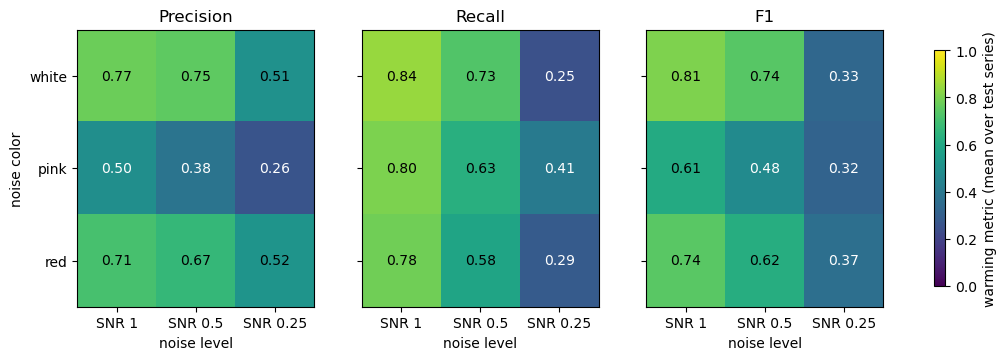

saved results/test_only/noise_heatmap_precision_recall_f1.png


In [14]:
# One figure for the report: precision, recall and F1 side by side (test split, winning config), shared 0-1 colour scale.
_ORDER_LEVELS = ["k1", "k0p5", "k0p25"]            # clean -> noisy
_ORDER_COLORS = ["white", "pink", "red"]
_LEVEL_LABELS = {"k1": "SNR 1", "k0p5": "SNR 0.5", "k0p25": "SNR 0.25"}   # relative to the cleanest level
_titles = {"precision": "Precision", "recall": "Recall", "f1": "F1"}
_test = MERGED_BY_SPLIT["test"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, key in zip(axes, ["precision", "recall", "f1"]):
    pv = (_test.pivot_table(index="color", columns="level", values=f"{key}_{OBJECTIVE}", aggfunc="mean")
               .reindex(index=_ORDER_COLORS, columns=_ORDER_LEVELS))
    im = ax.imshow(pv.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(_ORDER_LEVELS))); ax.set_xticklabels([_LEVEL_LABELS[l] for l in _ORDER_LEVELS])
    ax.set_yticks(range(len(_ORDER_COLORS))); ax.set_yticklabels(_ORDER_COLORS)
    ax.set_title(_titles[key]); ax.set_xlabel("noise level")
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            v = pv.values[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v < 0.5 else "black")
axes[0].set_ylabel("noise color")
fig.colorbar(im, ax=axes.tolist(), shrink=0.85, label=f"{OBJECTIVE} metric (mean over test series)")
out = os.path.join(TEST_ONLY_DIR, "noise_heatmap_precision_recall_f1.png")
fig.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print("saved", out)


## Applying the winning config to real NGRIP data

Everything above is synthetic (Melcher25 model output, see `Generate_Data_25events.ipynb`).
This section applies the exact same frozen `best_params` -- zero re-tuning -- to the real
NGRIP d18O record, scored against the real Dansgaard-Oeschger (DO) event catalog
(`DO_onsets_Rasmussen2014.csv` in ammonyte's data folder: the 25 main GI onsets (one per numbered interstadial, GI-1 ... GI-25) of Rasmussen et al. 2014, Table 2, GICC05modelext -- the file also holds all 34 in `all34_kyr_b2k`; it replaces the older `DO_events.csv` `main` column, several of whose entries did not sit at warming onsets), to see how the synthetic-tuned pipeline
performs on the actual real-world series it's ultimately meant for.

**Standardization.** `optuna_search.py`'s `load_split` standardizes every synthetic training
series independently to zero mean / **unit std** (`pyleoclim.utils.tsutils.standardize`,
default `scale=1`) before `pen` is ever tuned against it -- see that function's docstring,
which says explicitly that this is what lets the tuned params transfer to NGRIP at all,
*because NGRIP gets self-standardized the same way at application time*. So the correct
transfer here is NGRIP standardized to its own zero-mean/unit-std (`ngrip_win.standardize()`,
no `scale` argument) -- not rescaled to match the synthetic pool's raw (unstandardized) std.
Below we compare **raw** (NGRIP's own untouched scale, kept only for contrast) against
**standardized** (NGRIP self-standardized to std=1 -- the actual apples-to-apples setting
`pen` was tuned under).

**Warming only.** Optuna optimized `f1_warming`, and the DO onset catalog only lists warming
transitions -- there's no real cooling ground truth to score against. So detections are
classified by direction (`_classify_detected_directions`, this project's own classifier --
see that function's/`ruptures_transitions.py`'s docstring for why it's not the same as
ammonyte's own `jump_values` up/down sign convention) and only the warming-classified ones
are scored or plotted below, for both the raw-scale and standardized-scale NGRIP runs. An
"all directions" number is deliberately not reported -- it would be comparing detections
against ground truth that doesn't exist for the non-warming ones.

**Direction / orientation.** NGRIP's axis is age (kyr b2k), i.e. backwards in time, whereas the synthetic
data (and the classifier and optimization built on it) run forward in time. So NGRIP is first
time-reversed into forward time (next cell), after which the *unchanged* classifier is used as on the
synthetic splits. This is equivalent to ammonyte's own age-axis `jump_values == 1` convention (checked:
100% agreement for KS and KernelCPD). Detected times and DO events are then expressed in `-kyr b2k`.

In [15]:
import ammonyte as amt
from ammonyte.utils.metrics import evaluate_detection

# Reuse optuna_search.py's own direction classifier + tolerance constant, so the
# "warming" numbers below stay byte-for-byte consistent with how every synthetic split
# was scored (this project deliberately does NOT use ammonyte's own ruptures_transitions.py
# jump_values sign convention for direction -- see that file's module docstring).
sys.path.insert(0, os.path.join(METHODS_DIR, "optuna_search"))
from optuna_search import _classify_detected_directions, TOLERANCE

# Ammonyte ships its own copy of NGRIP.csv/DO_events.csv (verified byte-identical to this
# repo's data/ copy) plus a Series.from_csv loader -- use those directly instead of
# re-parsing the CSV by hand.
AMMONYTE_DATA_DIR = os.path.join(os.path.dirname(amt.__file__), "data")
ngrip_series = amt.Series.from_csv(os.path.join(AMMONYTE_DATA_DIR, "NGRIP.csv"))

do_df = pd.read_csv(os.path.join(AMMONYTE_DATA_DIR, "DO_onsets_Rasmussen2014.csv"), comment="#")   # 25 main GI onsets (Rasmussen 2014, Table 2)
do_gt_times = np.sort(do_df["main25_kyr_b2k"].dropna().values.astype(float))
do_gt_age = do_gt_times.copy()   # catalog ages (kyr b2k); never rebound, so cells can be re-run safely

print(f"NGRIP ({ngrip_series.value_name}, {ngrip_series.time_unit}): {len(ngrip_series.time)} points, "
      f"{ngrip_series.time.min():.2f}-{ngrip_series.time.max():.2f} kyr b2k")
print(f"DO events (warming only): {len(do_gt_times)}, "
      f"{do_gt_times.min():.2f}-{do_gt_times.max():.2f} kyr b2k")

Time axis values sorted in ascending order
Time axis values sorted in ascending order
NGRIP (δ¹⁸O, kyr b2k): 6112 points, 0.05-122.27 kyr b2k
DO events (warming only): 25, 14.69-115.37 kyr b2k


**Forward-time orientation (same as the synthetic data).** NGRIP's axis is *age* (kyr b2k, ascending =
going back in time), while every synthetic series runs forward in time (higher = warmer, warming = the
value going *up* through the array), which is the convention `_classify_detected_directions` and the
whole optimization assume. So before detection, NGRIP is time-reversed: `time_fwd = -age` (ascending,
i.e. negative kyr before present) with the values reversed, and the DO catalog times are mapped the same
way (`-age`). Detection, tolerance (0.5 kyr) and the unmodified direction classifier are then used
exactly as on the synthetic splits, with no sign flip anywhere. Detected times below are therefore
in `-kyr b2k`.

In [16]:
# Rebuild the age-axis window from the ORIGINAL objects every time, so this cell (and the ones above it) can be
# re-run in any order without flipping the series twice, then rebind the names every downstream cell uses.
# NGRIP is cut to exactly the DO-catalog range (no padding: like the synthetic series, the detector sees only the labelled span).
# Tested 0-5 kyr of padding: F1 0.87-0.89; >=10 kyr changes the standardization std and lowers F1.
ngrip_win_age = ngrip_series.slice([do_gt_age.min(), do_gt_age.max()])

def to_forward_time(series):
    """age-ascending Series -> forward-time Series (time = -age ascending, values reversed)"""
    return amt.Series(time=-series.time[::-1], value=series.value[::-1],
                      time_name="time (forward)", time_unit="-kyr b2k",
                      value_name=series.value_name, value_unit=series.value_unit,
                      label=f"{series.label} (forward time)", verbose=False)

ngrip_win = to_forward_time(ngrip_win_age)
ngrip_standardized_series = ngrip_win.standardize()
do_gt_times = np.sort(-do_gt_age)

print(f"forward NGRIP: {ngrip_win.time.min():.2f} to {ngrip_win.time.max():.2f} (-kyr b2k), "
      f"std of standardized = {ngrip_standardized_series.value.std():.3f}")
import collections
gt_dirs = _classify_detected_directions(ngrip_standardized_series.value, ngrip_standardized_series.time, do_gt_times, 9)
print("original (unflipped) classifier on the real DO onsets:", dict(collections.Counter(gt_dirs)))

forward NGRIP: -115.37 to -14.71 (-kyr b2k), std of standardized = 1.000
original (unflipped) classifier on the real DO onsets: {'ambiguous': 1, 'warming': 23, 'cooling': 1}


In [17]:
from ammonyte.core.transitions import DeterministicTransitions

NGRIP_UNFILTERED = {}   # label -> in-range detections before direction filtering (see below)

def score_ngrip(series, gt_times, algo, cost, pen, n_bkps, min_size, jump, tolerance, label):
    # series.ruptures(...) is ammonyte's own Series method -- returns a DeterministicTransitions
    # object. Runs on the series cut to the labeled range (ngrip_win / ngrip_standardized_series).
    transitions = series.ruptures(algo=algo, cost=cost, pen=pen, n_bkps=n_bkps,
                                   min_size=min_size, jump=jump)
    detected_all = np.asarray(transitions.jump_times, dtype=float)

    # Score only detections INSIDE the labeled range [gt_times.min(), gt_times.max()] --
    # (kept as a safeguard: with no padding it normally drops nothing). `tolerance` is a separate
    # concept -- it only controls point-matching distance within this range.
    in_range = (detected_all >= gt_times.min()) & (detected_all <= gt_times.max())
    n_dropped = (~in_range).sum()
    detected = detected_all[in_range]

    # Keep only detections OUR classifier calls warming -- see markdown above for why "all
    # directions" isn't reported: the DO onset catalog has no cooling ground truth to compare against.
    # `series` is NGRIP in FORWARD time (see the time-reversal cell above), the same orientation as
    # the synthetic data, so the original classifier applies unchanged (warming = value goes up).
    det_directions = _classify_detected_directions(series.value, series.time, detected, min_size)
    detected_warming = detected[det_directions == "warming"]
    NGRIP_UNFILTERED[label] = detected   # in-range detections before the direction filter
    print(f"--- {label}: {len(detected_all)} changepoints detected, "
          f"{n_dropped} outside the labeled range (dropped before scoring), {len(detected)} in "
          f"range, {len(detected_warming)} classified warming (scored below) ---")

    # evaluate_detection's own DetectionMetrics.__str__ prints ammonyte's formatted
    # precision/recall/F1 + true/false positive/negative tables.
    warming_metrics = evaluate_detection(detected=detected_warming, ground_truth=gt_times,
                                          tolerance=tolerance)
    print(warming_metrics)

    # Fresh warming-only DeterministicTransitions for plotting below -- NOT `transitions` as-is,
    # since that one still holds every detection under ammonyte's own up/down
    # jump_values sign convention, not our classifier's warming/cooling call.
    warming_transitions = DeterministicTransitions(
        series=series, jump_times=detected_warming, jump_values=np.ones(len(detected_warming)),
        method=transitions.method, method_args=transitions.method_args,
        label=f"{label} (warming only)",
    )

    return warming_transitions, detected_warming, warming_metrics


ngrip_common_kwargs = dict(algo=best_params["method"], cost=best_params["cost"], pen=best_params["pen"],
                            n_bkps=best_params["n_bkps"], min_size=best_params["min_size"],
                            jump=best_params["jump"])

ngrip_raw_transitions, ngrip_raw_detected_warming, ngrip_raw_warming_metrics = score_ngrip(
    ngrip_win, do_gt_times, tolerance=TOLERANCE, label="raw (NGRIP's own untouched scale)",
    **ngrip_common_kwargs)

print()
ngrip_standardized_transitions, ngrip_standardized_detected_warming, ngrip_standardized_warming_metrics = score_ngrip(
    ngrip_standardized_series, do_gt_times, tolerance=TOLERANCE,
    label="standardized (zero mean, unit std -- same scale pen was tuned on)", **ngrip_common_kwargs)

print(f"\nf1_warming: raw={ngrip_raw_warming_metrics.f1_score:.3f}  "
      f"standardized={ngrip_standardized_warming_metrics.f1_score:.3f}")
print("standardized is the methodologically correct comparison -- it's the scale pen was "
      "actually tuned against (see markdown above). raw is kept only to show what happens "
      "without it.")

--- raw (NGRIP's own untouched scale): 87 changepoints detected, 0 outside the labeled range (dropped before scoring), 87 in range, 34 classified warming (scored below) ---
Detection Evaluation Metrics
Metrics calculated within tolerance = 0.5

Performance Scores:
+-----------+---------+
| Metric    |   Value |
+===========+=========+
| Precision |  0.6765 |
+-----------+---------+
| Recall    |  0.92   |
+-----------+---------+
| F1 Score  |  0.7797 |
+-----------+---------+

Detection Counts:
+-----------------+---------+
| Category        |   Count |
+=================+=========+
| True Positives  |      23 |
+-----------------+---------+
| False Positives |      11 |
+-----------------+---------+
| False Negatives |       2 |
+-----------------+---------+

Summary:
  Detected: 34 | Ground Truth: 25


--- standardized (zero mean, unit std -- same scale pen was tuned on): 49 changepoints detected, 0 outside the labeled range (dropped before scoring), 49 in range, 21 classified warmin

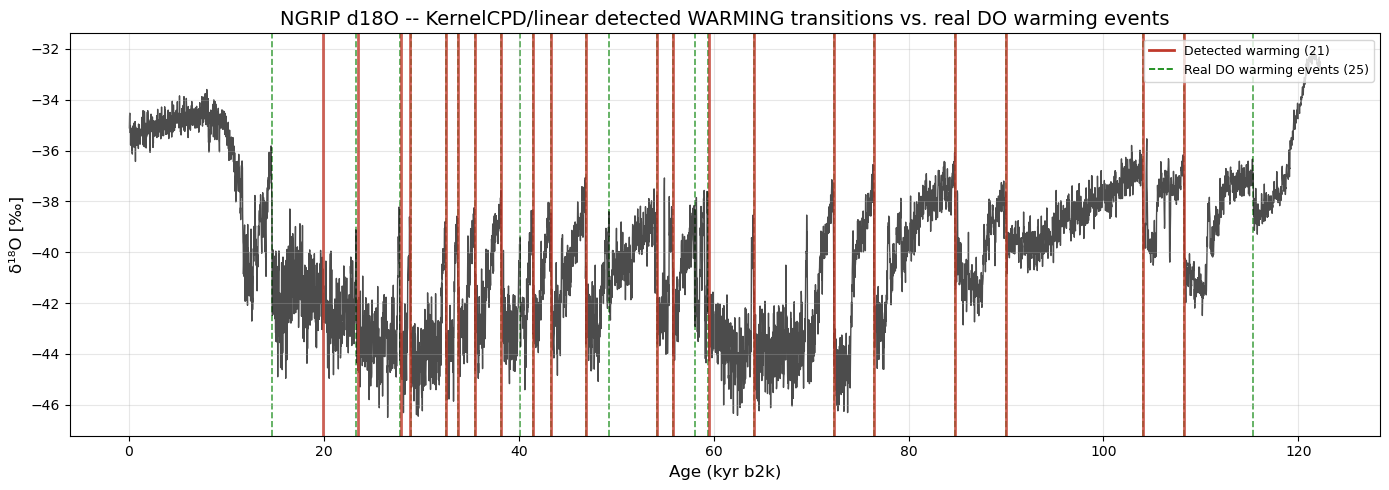

In [18]:
# Detection and direction were computed on the standardized, time-reversed (forward-time) record, but the
# figures show the FULL ORIGINAL NGRIP record (raw d18O in permil, 0-122 kyr) on its usual age axis (kyr b2k, ascending, positive).
# Detections exist only inside the DO-catalog window (the DO-catalog window). Mapping back is just
# age = -time_fwd for the detected times; the DO onsets are already stored as ages (do_gt_age).
def to_age_axis(fwd_transitions, label):
    age_series = ngrip_series           # the FULL original NGRIP record (0-122 kyr b2k, ascending), raw d18O in permil
    ages = np.sort(-np.asarray(fwd_transitions.jump_times, float))
    return DeterministicTransitions(series=age_series, jump_times=ages, jump_values=np.ones(len(ages)),
                                    method=fwd_transitions.method, method_args=fwd_transitions.method_args, label=label)

# warming_transitions (from score_ngrip) already holds ONLY the warming-classified detections
# -- plot with show_transitions="all" (single color, no up/down split) since direction is no
# longer ambiguous at this point. Real DO warming events are overlaid manually (green dashed).
kc_age_transitions = to_age_axis(ngrip_standardized_transitions, "KernelCPD warming (age axis)")
fig, ax = kc_age_transitions.plot(
    figsize=(14, 5), show_transitions="all", transition_color="#c0392b",
    legend_labels=[f"Detected warming ({len(ngrip_standardized_detected_warming)})"],
    title=f"NGRIP d18O -- {best_params['method']}/{best_params['cost']} "
          f"detected WARMING transitions vs. real DO warming events",
)
for t in do_gt_age:
    ax.axvline(t, color="green", linestyle="--", linewidth=1.2, alpha=0.7, zorder=0)
ax.plot([], [], color="green", linestyle="--", linewidth=1.2,
        label=f"Real DO warming events ({len(do_gt_age)})")
ax.set_xlabel("Age (kyr b2k)")
ax.legend(loc="upper right", fontsize=9)
plt.show()

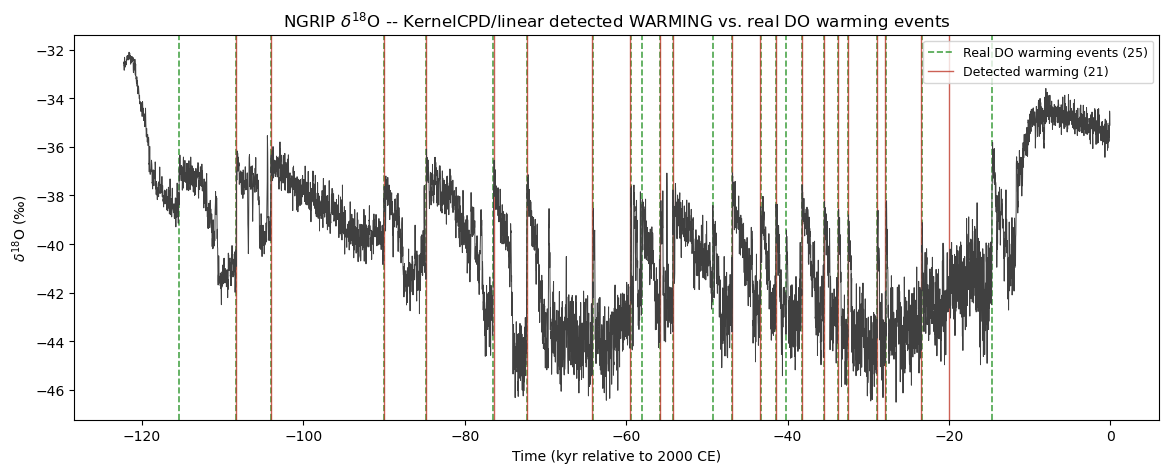

In [19]:
# Same detections, drawn in forward time (x = time relative to 2000 CE, i.e. -age: past on the left, present on the right), with the NGRIP
# record reversed to match. Warming then reads as the curve rising left-to-right, which is the orientation
# the detector and the direction classifier actually worked in. Nothing is recomputed: detections and DO onsets
# are already stored in forward time (-kyr b2k); only the full raw record is flipped for display.
fwd_time = -ngrip_series.time[::-1]
fwd_value = ngrip_series.value[::-1]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(fwd_time, fwd_value, color="0.25", lw=0.7)
for k, t in enumerate(do_gt_times):
    ax.axvline(t, color="green", ls="--", lw=1.2, alpha=0.7, zorder=0, label=f"Real DO warming events ({len(do_gt_times)})" if k == 0 else None)
for k, t in enumerate(ngrip_standardized_detected_warming):
    ax.axvline(t, color="#c0392b", lw=1.0, alpha=0.8, zorder=1, label=f"Detected warming ({len(ngrip_standardized_detected_warming)})" if k == 0 else None)
ax.set_xlabel("Time (kyr relative to 2000 CE)")
ax.set_ylabel(r"$\delta^{18}$O (‰)")
ax.set_title(f"NGRIP $\\delta^{{18}}$O -- {best_params['method']}/{best_params['cost']} detected WARMING vs. real DO warming events")
ax.legend(loc="upper right", fontsize=9)
plt.show()


In [20]:
# Side-by-side: synthetic splits (warming-direction metrics) vs. real NGRIP (raw + standardized).
ngrip_comparison = pd.DataFrame({
    'train': [train_df['precision_warming'].mean(), train_df['recall_warming'].mean(),
              train_df['f1_warming'].mean()],
    'validation': [val_df['precision_warming'].mean(), val_df['recall_warming'].mean(),
                   val_df['f1_warming'].mean()],
    'test': ([test_df['precision_warming'].mean(), test_df['recall_warming'].mean(),
              test_df['f1_warming'].mean()] if test_df is not None else [np.nan, np.nan, np.nan]),
    'NGRIP (raw)': [ngrip_raw_warming_metrics.precision, ngrip_raw_warming_metrics.recall,
                     ngrip_raw_warming_metrics.f1_score],
    'NGRIP (standardized)': [ngrip_standardized_warming_metrics.precision,
                              ngrip_standardized_warming_metrics.recall,
                              ngrip_standardized_warming_metrics.f1_score],
}, index=['precision_warming', 'recall_warming', 'f1_warming'])
ngrip_comparison

,train,validation,test,NGRIP (raw),NGRIP (standardized)
precision_warming,0.570355,0.575302,0.565033,0.676471,0.952381
recall_warming,0.642572,0.565169,0.599665,0.920000,0.800000
f1_warming,0.569107,0.532451,0.564344,0.779661,0.869565


## Notes / limitations

- The precision-recall scatter and F1 heatmap are **train-only**: `optuna_trials.csv` is the
  only file with a score for every (method, cost, pen/n_bkps, min_size) combo Optuna tried.
- `best_validation_raw.csv` / `best_test_raw.csv` only ever hold the single **winning**
  config's per-seed scores. Validation is a one-time sanity check on the winner (not re-run
  per candidate, or it would stop being a useful check), and test is deliberately scored
  exactly once (see `evaluate_test.py`'s docstring) -- so there's no validation/test analog
  of the search-space plots above unless detection is deliberately re-run for other configs
  against those splits.
- Low `count` cells in the noise-condition tables/heatmaps (some conditions have only
  1-3 seeds) mean those means are noisy -- treat single-digit-count cells as suggestive,
  not conclusive.

## Example detection plot + ground-truth table (one test series, 300 dpi)

One held-out test series (default: the one whose `f1_<objective>` is closest to the median, so it isn't cherry-picked) with the winning config's **warming** detections scored against the synthetic **warming** ground truth (the search objective). Each true event is a **true positive** (a detection within the shaded `TOLERANCE` window around it -- it need not sit exactly on the dashed line) or a **false negative**; each detection with no true event within tolerance is a **false positive**. Same one-to-one closest-match rule as `optuna_search._matched_timing_errors`. Axes carry major (annotated) and minor ticks.


row 12: TP=18 FN=4 FP=21 precision=0.462 recall=0.818 (saved: p=0.462 r=0.818)
warming events only


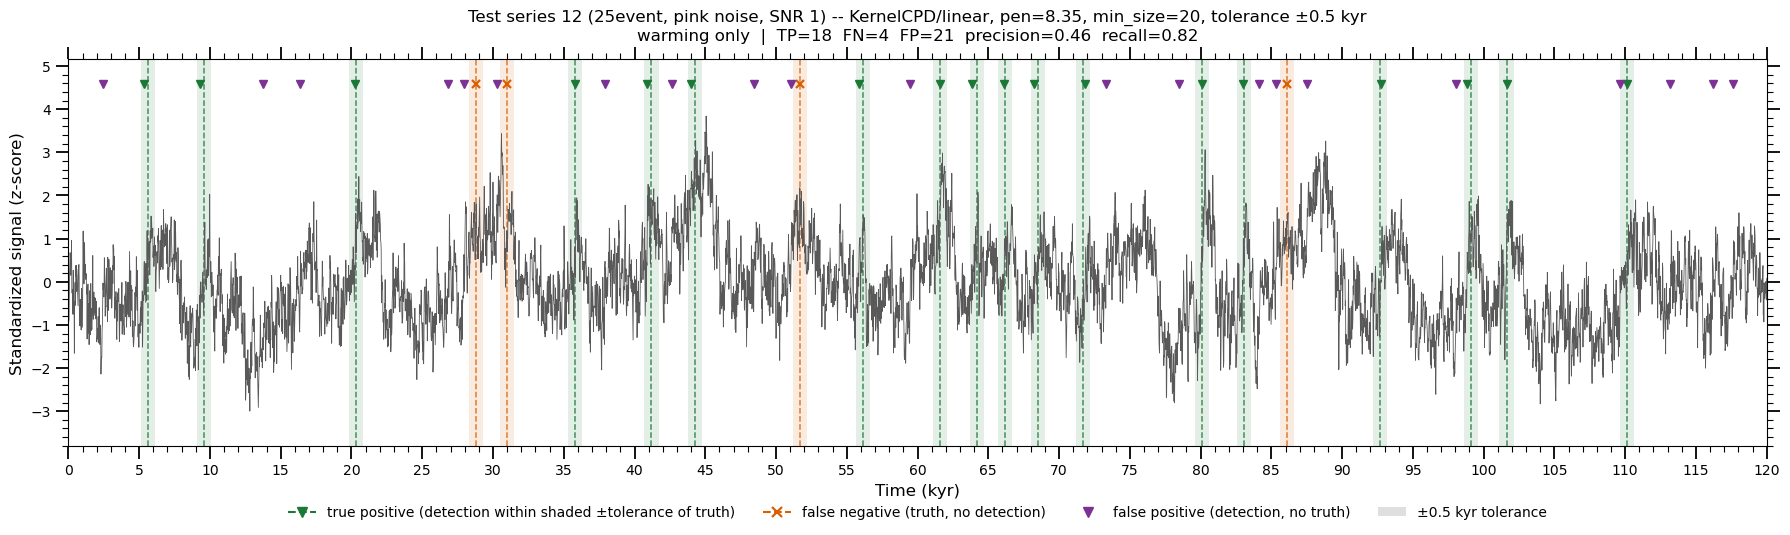

,gt_time_kyr,direction,detected_time_kyr,error_kyr,outcome
0,NaN,warming,2.42,NaN,false positive
1,5.64,warming,5.34,0.30,true positive
2,9.56,warming,9.32,0.24,true positive
3,NaN,warming,13.78,NaN,false positive
4,NaN,warming,16.38,NaN,false positive
5,20.34,warming,20.28,0.06,true positive
6,NaN,warming,26.84,NaN,false positive
7,NaN,warming,27.94,NaN,false positive
8,28.78,warming,NaN,NaN,false negative
9,NaN,warming,30.26,NaN,false positive


In [21]:
import optuna_search as o
from matplotlib.patches import Patch
from matplotlib.ticker import AutoMinorLocator, MultipleLocator

EXAMPLE_ROW = None   # None -> median-f1_all test series; or set a row number
DPI = 300
TEST_PATH = os.path.join("..", "..", "noisier_data", "train_test_split_data", "test.npz")
MANIFEST = os.path.join("..", "..", "noisier_data", "train_test_split_data", "test_manifest.csv")
OUT_DIR = os.path.join(RESULTS_DIR, "example_plot")
os.makedirs(OUT_DIR, exist_ok=True)

row = EXAMPLE_ROW if EXAMPLE_ROW is not None else int((test_df[f"f1_{OBJECTIVE}"] - test_df[f"f1_{OBJECTIVE}"].median()).abs().idxmin())
t, db, gt_all, gd_all, _ = o.load_split(TEST_PATH)
value, gt, gdir = db[row], gt_all[row], gd_all[row]
detected, _ = o._detect(t, value, best_params["method"], best_params["cost"], best_params["pen"],
                        best_params["n_bkps"], best_params["min_size"], best_params["jump"], o.DEFAULT_MAX_CALL_SECONDS)
ddir = dict(zip(detected, o._classify_detected_directions(value, t, detected, best_params["min_size"])))
tol = o.TOLERANCE

# score only the objective's direction (warming): keep warming ground truth and warming-classified detections
gt = gt[gdir == OBJECTIVE]
gdir = gdir[gdir == OBJECTIVE]
detected = np.array([d for d in detected if ddir[d] == OBJECTIVE])

# one-to-one match within tolerance, closest (detection, truth) pairs first. This pairs a truth with its
# nearest detection; the scorer's detection-order greedy rule gives the same TP/FP/FN counts on every test
# series, it only can assign a farther detection to a truth, which would inflate the timing error slightly.
matched, used_det = {}, set()
for _, i, j in sorted((abs(g - d), i, j) for i, d in enumerate(detected) for j, g in enumerate(gt) if abs(g - d) <= tol):
    if i not in used_det and j not in matched:
        used_det.add(i)
        matched[j] = detected[i]
fp = [d for i, d in enumerate(detected) if i not in used_det]
n_tp, n_fn, n_fp = len(matched), len(gt) - len(matched), len(fp)
prec, rec = n_tp / max(n_tp + n_fp, 1), n_tp / max(len(gt), 1)
print(f"row {row}: TP={n_tp} FN={n_fn} FP={n_fp} precision={prec:.3f} recall={rec:.3f} "
      f"(saved: p={test_df.precision_warming[row]:.3f} r={test_df.recall_warming[row]:.3f})")

# ground-truth table
table = pd.DataFrame(
    [dict(gt_time_kyr=gt[j], direction=gdir[j], detected_time_kyr=matched.get(j, np.nan),
          error_kyr=abs(matched[j] - gt[j]) if j in matched else np.nan,
          outcome="true positive" if j in matched else "false negative") for j in range(len(gt))]
    + [dict(gt_time_kyr=np.nan, direction=ddir[d], detected_time_kyr=d, error_kyr=np.nan, outcome="false positive")
       for d in fp]
)
table = (table.assign(_t=table.gt_time_kyr.fillna(table.detected_time_kyr)).sort_values("_t")
              .drop(columns="_t").round(3).reset_index(drop=True))
table.to_csv(os.path.join(OUT_DIR, f"ground_truth_table_row{row}.csv"), index=False)

# plot
C_TP, C_FN, C_FP = "#1b7837", "#d95f02", "#7b3294"
fig, ax = plt.subplots(figsize=(18, 5.5))
ax.plot(t, value, color="0.35", lw=0.6, zorder=2)
ymin, ymax = value.min(), value.max()
pad = 0.12 * (ymax - ymin)
ax.set_ylim(ymin - pad, ymax + pad * 1.6)
ax.set_xlim(t[0], t[-1])
ymark = ymax + pad * 0.9
for j, g in enumerate(gt):
    ax.axvspan(g - tol, g + tol, color=C_TP if j in matched else C_FN, alpha=0.12, lw=0, zorder=0)   # tolerance window
    ax.axvline(g, color=C_TP if j in matched else C_FN, lw=1.1, ls="--", alpha=0.8, zorder=1)
    if j not in matched:
        ax.plot(g, ymark, marker="x", color=C_FN, ms=6, mew=1.6, zorder=3, clip_on=False)
ax.plot(list(matched.values()), [ymark] * n_tp, ls="none", marker="v", color=C_TP, ms=6, zorder=3, clip_on=False)
ax.plot(fp, [ymark] * n_fp, ls="none", marker="v", color=C_FP, ms=6, zorder=3, clip_on=False)

ax.xaxis.set_major_locator(MultipleLocator(5)); ax.xaxis.set_minor_locator(MultipleLocator(1))
ax.yaxis.set_major_locator(MultipleLocator(1)); ax.yaxis.set_minor_locator(AutoMinorLocator(5))
ax.tick_params(which="major", length=9, width=1.3, labelsize=10, top=True, right=True)
ax.tick_params(which="minor", length=4.5, width=0.8, top=True, right=True)
ax.set_xlabel("Time (kyr)", fontsize=12)
ax.set_ylabel("Standardized signal (z-score)", fontsize=12)
print(f"{OBJECTIVE} events only")
# sigma_noise = gap / k (generate_noisier_data.py) -> SNR = k
SNR_LABEL = {"k1": "1", "k0p5": "0.5", "k0p25": "0.25"}
meta = pd.read_csv(MANIFEST).iloc[row]
ax.set_title(f"Test series {row} ({meta['source']}, {meta['color']} noise, SNR {SNR_LABEL[meta['level']]}) -- "
             f"{best_params['method']}/{best_params['cost']}, pen={best_params['pen']:.2f}, "
             f"min_size={best_params['min_size']}, tolerance \u00b1{tol} kyr\n"
             f"{OBJECTIVE} only  |  TP={n_tp}  FN={n_fn}  FP={n_fp}  precision={prec:.2f}  recall={rec:.2f}", fontsize=12, pad=14)
ax.legend(handles=[
    Line2D([0], [0], color=C_TP, ls="--", marker="v", ms=7, label="true positive (detection within shaded \u00b1tolerance of truth)"),
    Line2D([0], [0], color=C_FN, ls="--", marker="x", ms=7, mew=1.6, label="false negative (truth, no detection)"),
    Line2D([0], [0], color=C_FP, ls="none", marker="v", ms=7, label="false positive (detection, no truth)"),
    Patch(facecolor="0.5", alpha=0.25, label=f"\u00b1{tol} kyr tolerance"),
], loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False, fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, f"detection_example_row{row}_{DPI}dpi.png"), dpi=DPI, bbox_inches="tight")
fig.savefig(os.path.join(OUT_DIR, f"detection_example_row{row}_{DPI}dpi.pdf"), bbox_inches="tight")
plt.show()
table

## Bare time series + TP/FP/FN table (one series, one parameter set, warming only)

The plot shows the series with nothing on it. The table lists the winning config's warming detections against the warming ground truth (TP = matched within tolerance, FN = missed truth, FP = extra detection). The cell asserts F1 < 0.6. Run after the example-plot cell above (needs `o`, `best_params`, `OBJECTIVE`, `RESULTS_DIR`).

KernelCPD/linear pen=8.35 min_size=20 tolerance=0.5 kyr | series 12, warming only
TP=18 FN=4 FP=21 precision=0.46 recall=0.82 F1=0.59


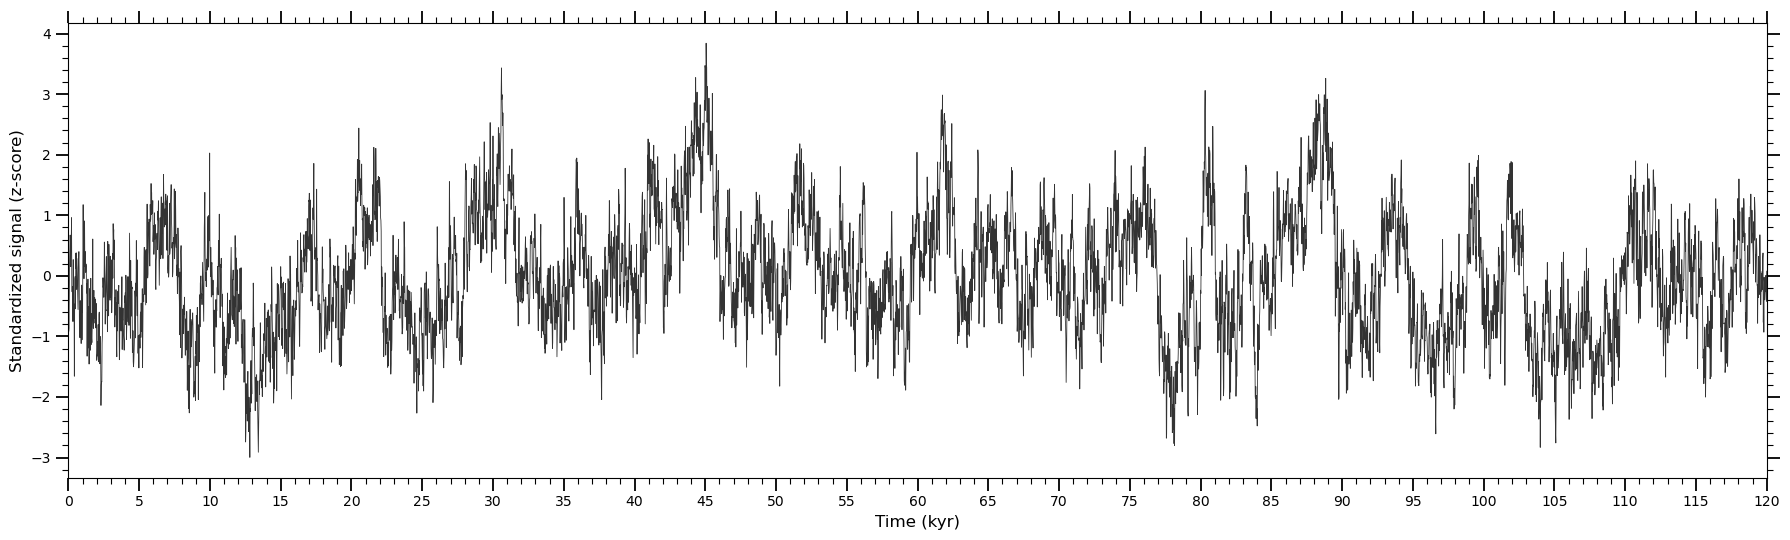

,gt_time_kyr,detected_time_kyr,outcome
0,NaN,2.42,FP
1,5.64,5.34,TP
2,9.56,9.32,TP
3,NaN,13.78,FP
4,NaN,16.38,FP
5,20.34,20.28,TP
6,NaN,26.84,FP
7,NaN,27.94,FP
8,28.78,NaN,FN
9,NaN,30.26,FP


In [22]:
EXAMPLE_ROW = 12   # test series; F1 must stay < F1_MAX for the supervisor's example
F1_MAX = 0.6
PEN = None         # None -> optuna best (8.35); otherwise override the penalty
DPI = 300
TEST_PATH = os.path.join("..", "..", "noisier_data", "train_test_split_data", "test.npz")
OUT_DIR = os.path.join(RESULTS_DIR, "example_plot")
os.makedirs(OUT_DIR, exist_ok=True)

t, db, gt_all, gd_all, _ = o.load_split(TEST_PATH)
row = EXAMPLE_ROW
value = db[row]
gt = gt_all[row][gd_all[row] == OBJECTIVE]            # warming ground truth only
bp = dict(best_params, pen=PEN) if PEN is not None else best_params
detected, _ = o._detect(t, value, bp["method"], bp["cost"], bp["pen"], bp["n_bkps"], bp["min_size"], bp["jump"],
                        o.DEFAULT_MAX_CALL_SECONDS)
ddir = dict(zip(detected, o._classify_detected_directions(value, t, detected, bp["min_size"])))
detected = np.array([d for d in detected if ddir[d] == OBJECTIVE])   # warming detections only
tol = o.TOLERANCE

matched, used = {}, set()
for _, i, j in sorted((abs(g - d), i, j) for i, d in enumerate(detected) for j, g in enumerate(gt) if abs(g - d) <= tol):
    if i not in used and j not in matched:
        used.add(i); matched[j] = detected[i]
fp = [d for i, d in enumerate(detected) if i not in used]
n_tp, n_fn, n_fp = len(matched), len(gt) - len(matched), len(fp)
prec, rec = n_tp / max(n_tp + n_fp, 1), n_tp / len(gt)
f1 = 2 * prec * rec / (prec + rec)
print(f"{bp['method']}/{bp['cost']} pen={bp['pen']:.2f} min_size={bp['min_size']} tolerance={tol} kyr | series {row}, {OBJECTIVE} only")
print(f"TP={n_tp} FN={n_fn} FP={n_fp} precision={prec:.2f} recall={rec:.2f} F1={f1:.2f}")
assert f1 < F1_MAX, f"F1={f1:.2f} is not below {F1_MAX}; pick another EXAMPLE_ROW"

# bare time series: nothing drawn on it
fig, ax = plt.subplots(figsize=(18, 5.5))
ax.plot(t, value, color="0.2", lw=0.6)
ax.set_xlim(t[0], t[-1])
ax.xaxis.set_major_locator(MultipleLocator(5)); ax.xaxis.set_minor_locator(MultipleLocator(1))
ax.yaxis.set_major_locator(MultipleLocator(1)); ax.yaxis.set_minor_locator(AutoMinorLocator(5))
ax.tick_params(which="major", length=9, width=1.3, labelsize=10, top=True, right=True)
ax.tick_params(which="minor", length=4.5, width=0.8, top=True, right=True)
ax.set_xlabel("Time (kyr)", fontsize=12)
ax.set_ylabel("Standardized signal (z-score)", fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, f"bare_series_row{row}_{DPI}dpi.png"), dpi=DPI, bbox_inches="tight")
fig.savefig(os.path.join(OUT_DIR, f"bare_series_row{row}_{DPI}dpi.pdf"), bbox_inches="tight")
plt.show()

# table: one row per ground-truth event (TP / FN) and per extra detection (FP), time-ordered
table = pd.DataFrame(
    [dict(gt_time_kyr=gt[j], detected_time_kyr=matched.get(j, np.nan),
          outcome="TP" if j in matched else "FN") for j in range(len(gt))]
    + [dict(gt_time_kyr=np.nan, detected_time_kyr=d, outcome="FP") for d in fp]
)
table = (table.assign(_t=table.gt_time_kyr.fillna(table.detected_time_kyr)).sort_values("_t")
              .drop(columns="_t").round(2).reset_index(drop=True))
# CSV: metadata block on top (# lines; read back with pd.read_csv(path, comment="#")), then the table
meta = [f"series: test row {row} ({OBJECTIVE} only)",
        f"method: {bp['method']}/{bp['cost']}, pen={bp['pen']:.2f}, min_size={bp['min_size']}",
        f"tolerance_kyr: {tol}",
        f"n_ground_truth: {len(gt)}, n_detected: {len(detected)}",
        f"TP: {n_tp}, FP: {n_fp}, FN: {n_fn}",
        f"precision: {prec:.3f}, recall: {rec:.3f}, F1: {f1:.3f}"]
csv_path = os.path.join(OUT_DIR, f"detection_table_row{row}_pen{bp['pen']:.2f}.csv")
with open(csv_path, "w") as fh:
    fh.write("".join(f"# {m}\n" for m in meta))
table.to_csv(csv_path, mode="a", index=False)
print("\n".join(meta))
table